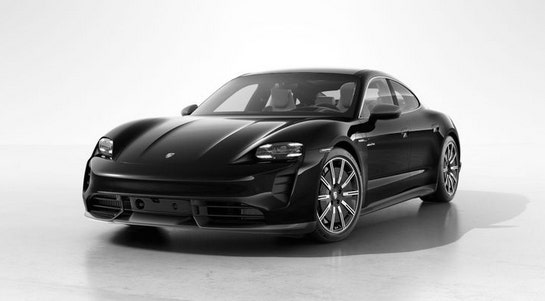

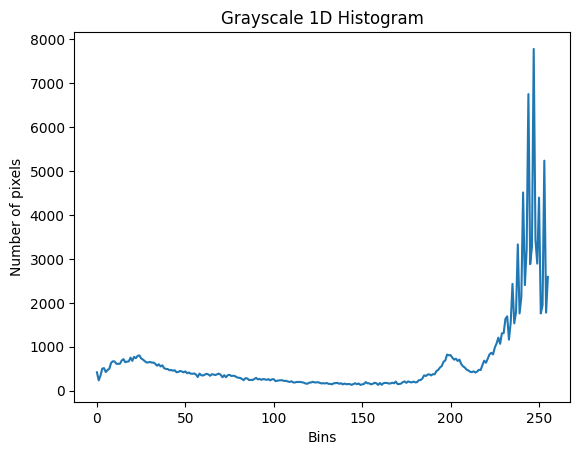

image.shape : (301, 545)
hist.shape : (256,)
hist.sum() : 164045.0
hist.max() : 7776.0 hist.min() : 132.0


In [ ]:
import cv2
from matplotlib import pyplot as plt

grayImage = cv2.imread('포르쉐타이칸.jpeg', cv2.IMREAD_GRAYSCALE)
cv2_imshow(grayImage)

hist = cv2.calcHist([grayImage], [0], None, [256], [0, 256])

plt.title("Grayscale 1D Histogram")
plt.xlabel("Bins")
plt.ylabel("Number of pixels")
plt.plot(hist)
plt.show()

print("image.shape :", grayImage.shape)
print("hist.shape :", hist.shape)
print("hist.sum() :", hist.sum())
print("hist.max() :", hist.max(), "hist.min() :", hist.min())

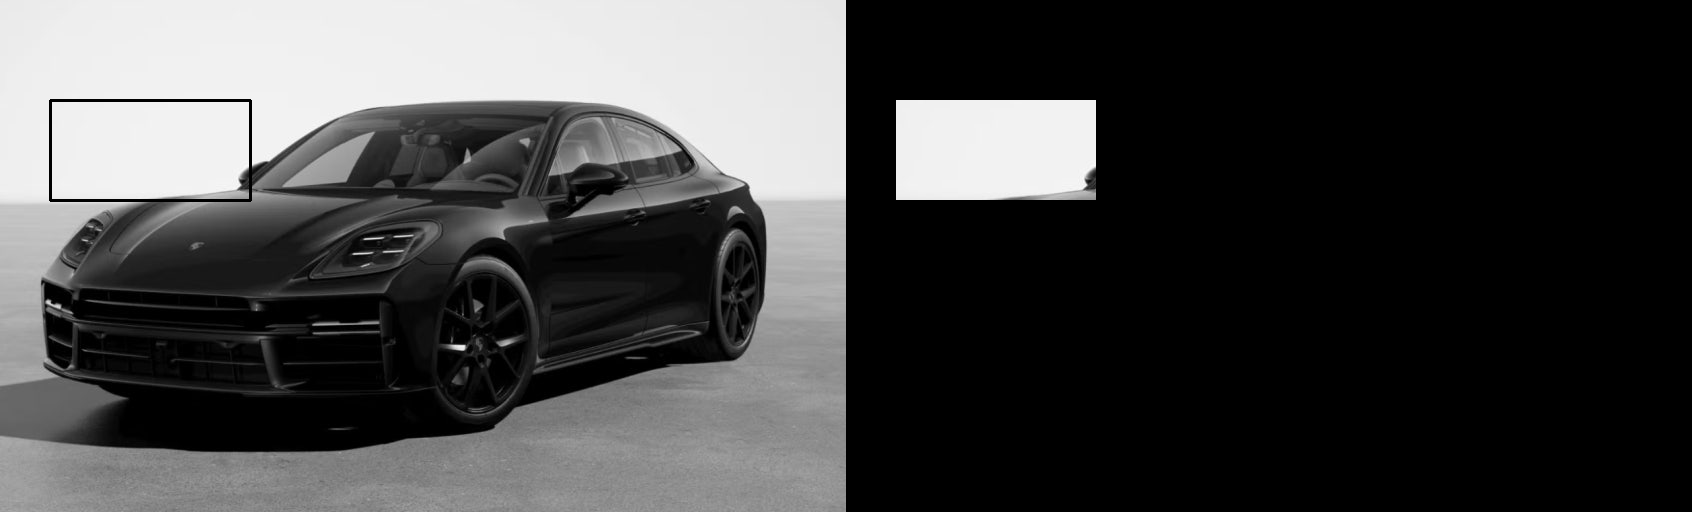

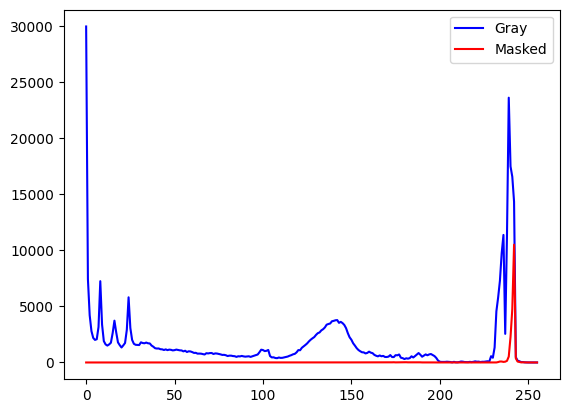

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow
import matplotlib.pyplot as plt

grayImage = cv2.imread('포르쉐파나메라.jpeg', cv2.IMREAD_GRAYSCALE)
x, y, w, h = 50, 100, 200, 100
mask = np.zeros(grayImage.shape[:2], np.uint8)
mask[y:y+h, x:x+w] = 255
maskedImage = cv2.bitwise_and(grayImage, grayImage, mask=mask)

grayHist = cv2.calcHist([grayImage], [0], None, [256], [0, 256])
maskHist = cv2.calcHist([grayImage], [0], mask, [256], [0, 256])

canvas = grayImage.copy()
cv2.rectangle(canvas, (x, y), (x+w, y+h), (0, 0, 0), 2)
cv2_imshow(cv2.hconcat([canvas, maskedImage]))

plt.plot(grayHist, color='b', label='Gray')
plt.plot(maskHist, color='r', label='Masked')
plt.legend()
plt.show()

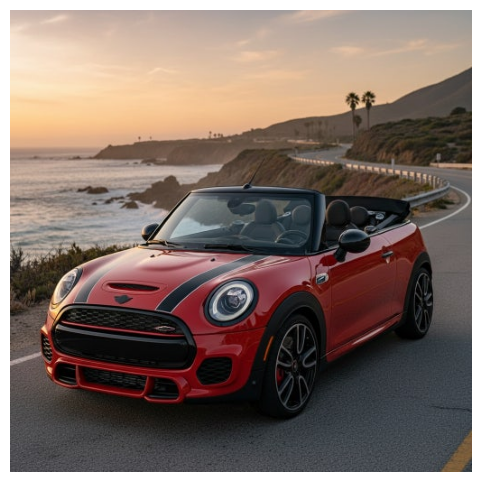

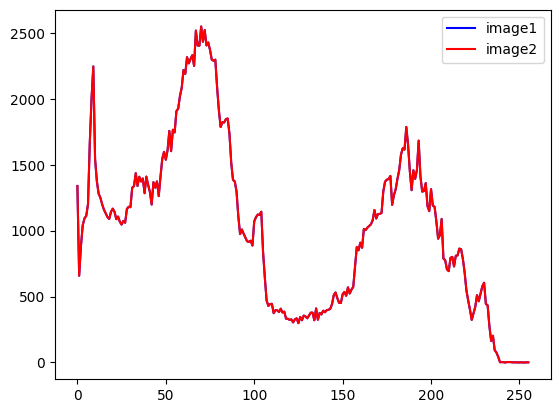

In [ ]:
import cv2
import matplotlib.pyplot as plt

img1 = cv2.imread('미니쿠퍼.jpeg', cv2.IMREAD_GRAYSCALE)
img2 = cv2.imread('미니쿠퍼.jpeg', cv2.IMREAD_GRAYSCALE)

hist1 = cv2.calcHist([img1], [0], None, [256], [0, 256])
hist2 = cv2.calcHist([img2], [0], None, [256], [0, 256])

img_color = cv2.imread('미니쿠퍼.jpeg')
plt.figure(figsize=(6, 6))
plt.imshow(cv2.cvtColor(img_color, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.show()

plt.plot(hist1, color='b', label='image1')
plt.plot(hist2, color='r', label='image2')
plt.legend()
plt.show()

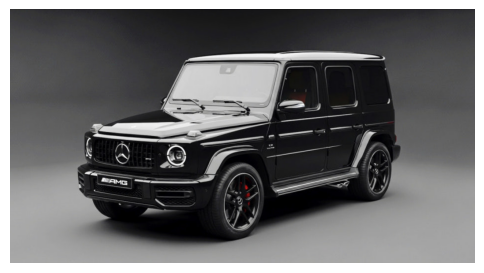

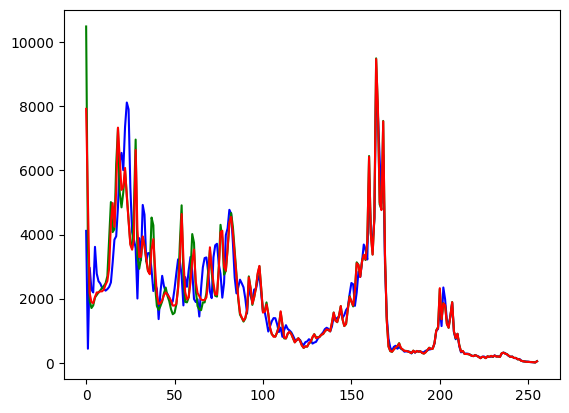

In [ ]:
import cv2
import matplotlib.pyplot as plt

img = cv2.imread('지바겐.jpeg')

plt.figure(figsize=(6, 6))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.show()

for col, color in zip(cv2.split(img), ('b', 'g', 'r')):
    plt.plot(cv2.calcHist([col], [0], None, [256], [0, 256]), color=color)

plt.show()

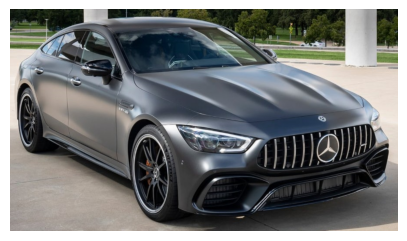

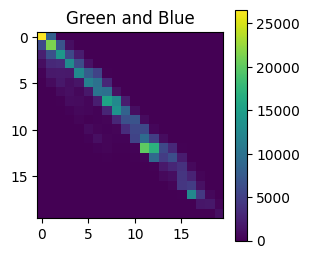

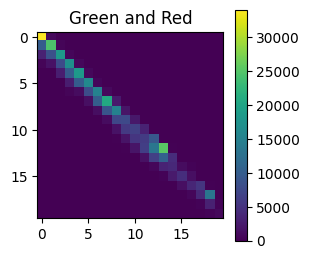

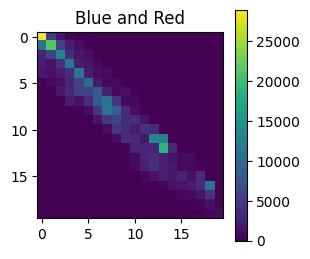

In [ ]:
import cv2
import matplotlib.pyplot as plt

img = cv2.imread('벤츠Amg.jpeg')
bins = 20

plt.figure(figsize=(5, 5))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.show()

for ch, title in zip([[1, 0], [1, 2], [0, 2]], ["Green and Blue", "Green and Red", "Blue and Red"]):
    plt.figure(figsize=(3, 3))
    plt.title(title)
    hist = cv2.calcHist([img], ch, None, [bins, bins], [0, 256, 0, 256])
    plt.imshow(hist, interpolation="nearest")
    plt.colorbar()
    plt.show()

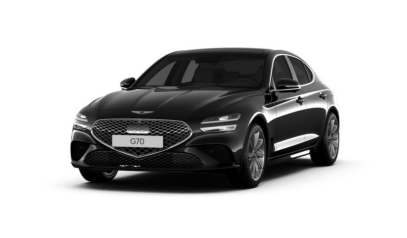

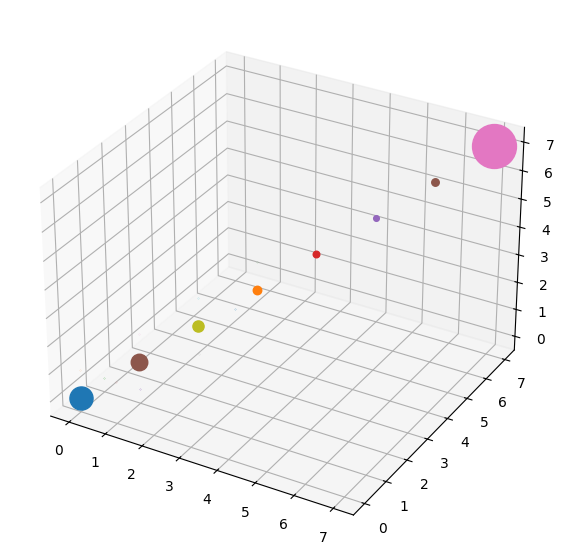

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread('g70.jpeg')

plt.figure(figsize=(5, 5))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.show()

hist3D = cv2.calcHist([img], [0, 1, 2], None, [8, 8, 8], [0, 256, 0, 256, 0, 256])
ratio = 1000 / np.max(hist3D)

fig = plt.figure (figsize=(7, 7))
ax = fig.add_subplot(111, projection="3d")

for b, p, r in np.ndindex(hist3D.shape):
    if hist3D[b, p, r] > 0:
        ax.scatter(b, p, r, s=ratio * hist3D[b, p, r])

plt.show()

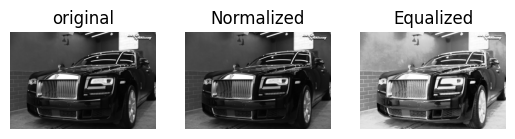

In [ ]:
import cv2
import matplotlib.pyplot as plt

img = cv2.imread('롤스로이스고스트.jpeg', cv2.IMREAD_GRAYSCALE)
norm = cv2.normalize(img, None, 0, 255, cv2.NORM_MINMAX)
eq = cv2.equalizeHist(norm)

for i, t, d in zip(range(1, 4), ['original', 'Normalized', 'Equalized'], [img, norm, eq]):
    plt.subplot(1, 3, i), plt.imshow(d, cmap='gray'), plt.title(t), plt.axis('off')
plt.show()

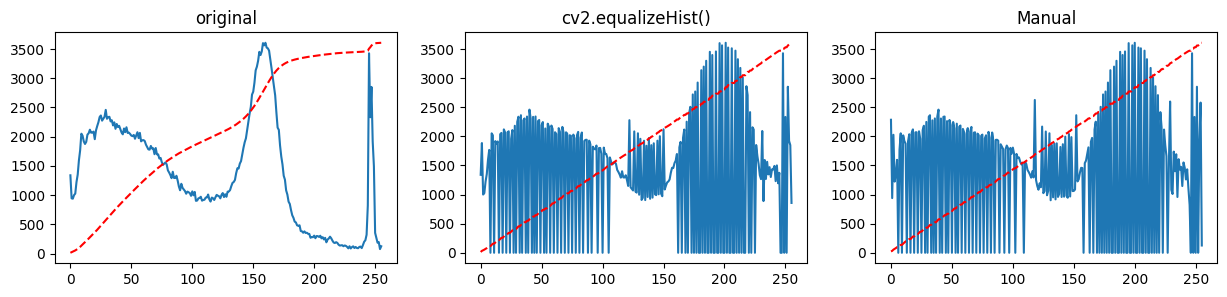

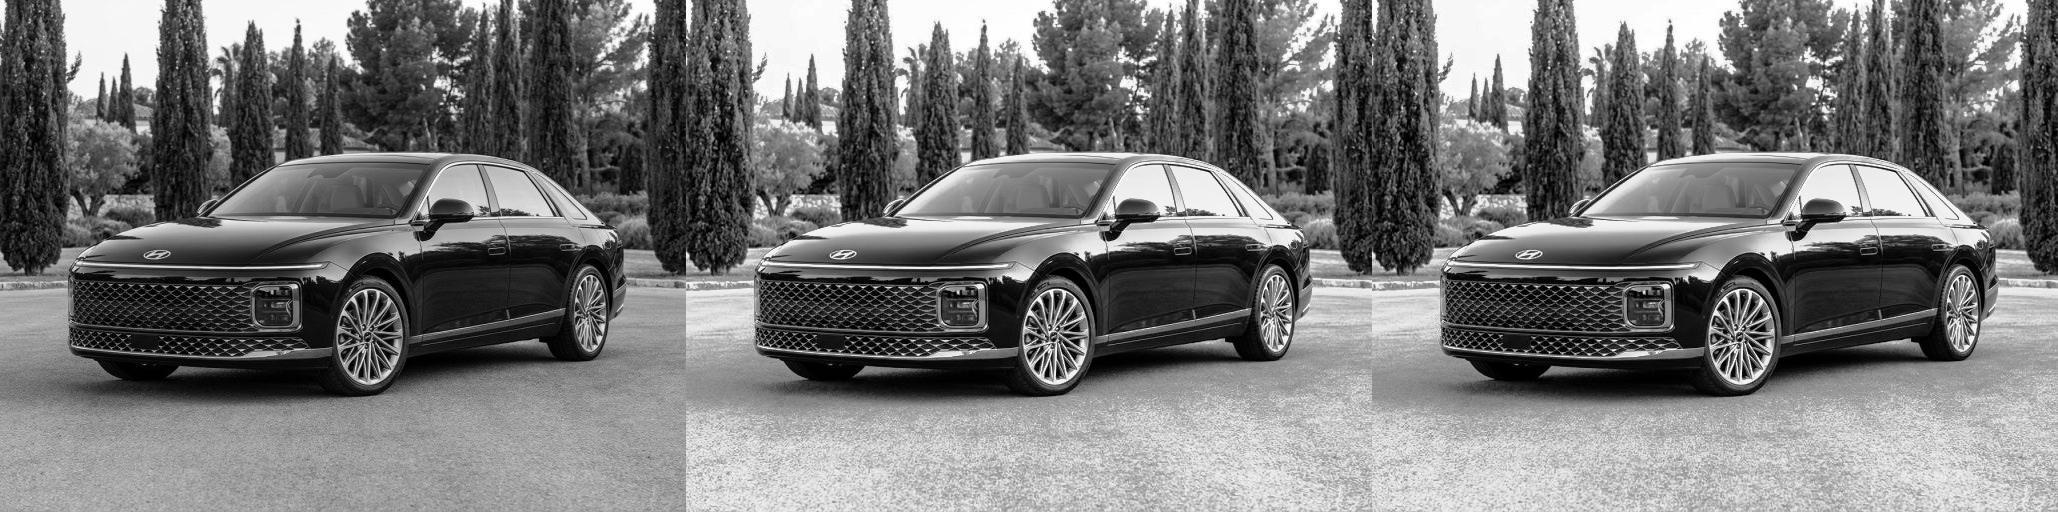

In [ ]:
import cv2
from google.colab.patches import cv2_imshow
import numpy as np
import matplotlib.pyplot as plt

image = cv2.imread('그랜저.jpeg', cv2.IMREAD_GRAYSCALE)

cvEqImage = cv2.equalizeHist(image)
hist = cv2.calcHist([image], [0], None, [256], [0, 256])
CDF = hist.cumsum()
maskedCDF = np.ma.masked_equal(CDF, 0)
maskedCDF = (maskedCDF - maskedCDF.min()) / (maskedCDF.max() - maskedCDF.min()) * 255
manEqImage = np.ma.filled(maskedCDF, 0).astype('uint8')[image]

hists = {'original' : hist, 'cv2.equalizeHist()' : cv2.calcHist([cvEqImage], [0], None, [256], [0, 256]), 'Manual' : cv2.calcHist([manEqImage], [0], None, [256], [0, 256])}
plt.figure(figsize=(15, 3))
for i, (title, h) in enumerate(hists.items()):
    plt.subplot(1, 3, i + 1)
    plt.title(title)
    plt.plot(h)
    plt.plot(np.cumsum(h) / h.sum() * h.max(), 'r--')
plt.show()

cv2_imshow(cv2.hconcat([image, cvEqImage, manEqImage]))

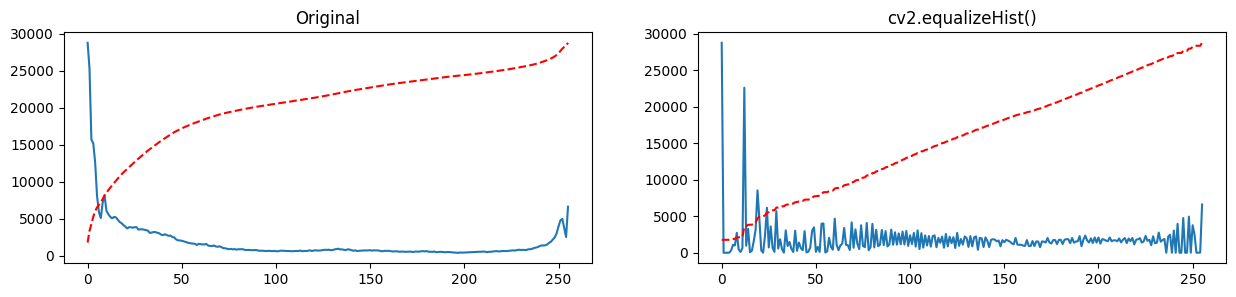

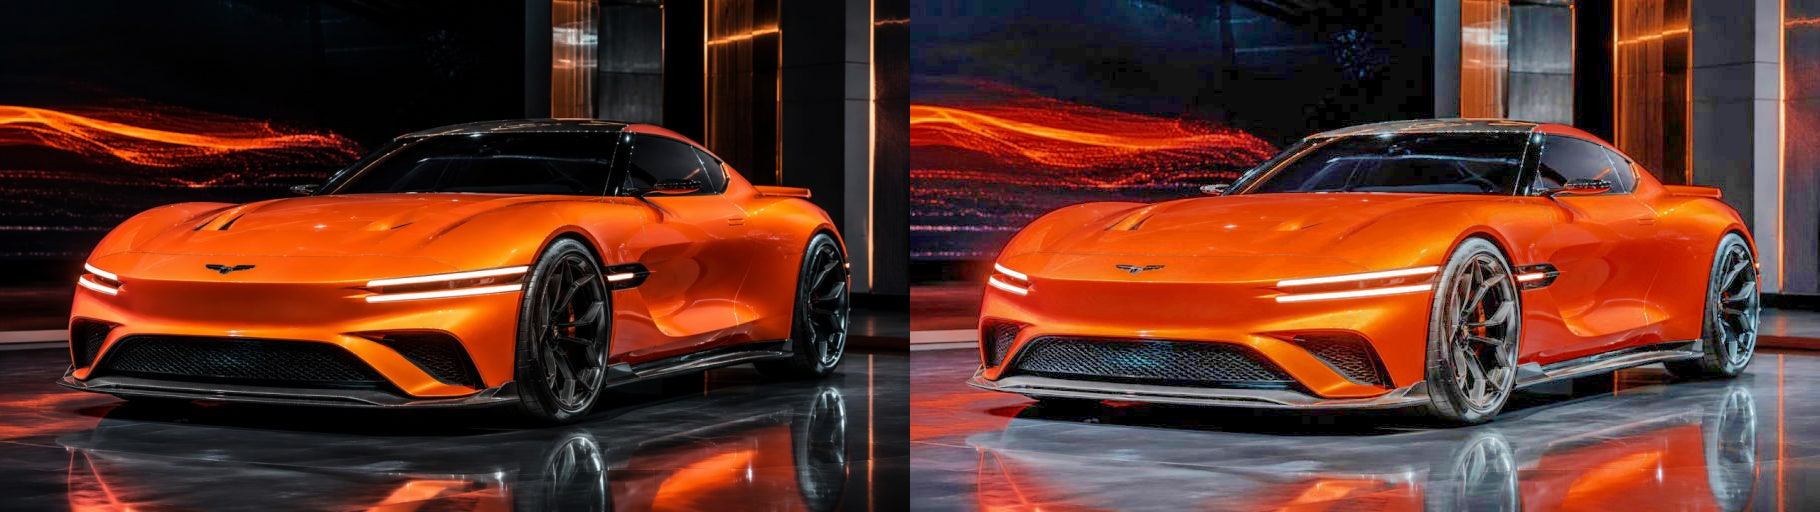

In [ ]:
import cv2
from google.colab.patches import cv2_imshow
import numpy as np
import matplotlib.pyplot as plt

image = cv2.imread('제네시스.jpeg')
hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
hsv[:, :, 2] = cv2.equalizeHist(hsv[:, :, 2])
eqImage = cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)

h1, h2 = cv2.calcHist([image], [2], None, [256], [0, 256]), cv2.calcHist([eqImage], [2], None, [256], [0, 256])

plt.figure(figsize=(15, 3))
for i, (title, h) in enumerate({'Original' : h1, 'cv2.equalizeHist()': h2}.items()):
    plt.subplot(1, 2, i + 1), plt.title(title), plt.plot(h)
    plt.plot(np.cumsum(h) / h.sum() * h.max(), 'r--')
plt.show()

cv2_imshow(cv2.hconcat([image, eqImage]))

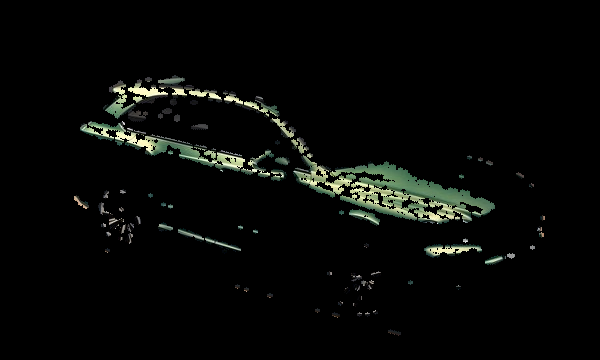

In [ ]:
import cv2
from google.colab.patches import cv2_imshow
import numpy as np
import matplotlib.pyplot as plt

image = cv2.imread('벤틀리.jpeg')
hsvImage = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
draw = image.copy()

def masking(bp):
    disc = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
    cv2.filter2D(bp, -1, disc, bp)
    _, mask = cv2.threshold(bp, 1, 255, cv2.THRESH_BINARY)
    result = cv2.bitwise_and(image, image, mask=mask)
    cv2_imshow(result)

def BackProject_cv(hist_roi):
    bp = cv2.calcBackProject([hsvImage], [0, 1], hist_roi, [0, 100, 0, 256], 1)
    bp = bp.reshape(hsvImage.shape[:2])
    cv2.normalize(bp, bp, 0, 255, cv2.NORM_MINMAX)
    bp = bp.astype(np.uint8)
    masking(bp)

(x, y, w, h) = (215, 80, 65, 65)
if w > 0 and h > 0:
    roi = draw[y:y+h, x:x+w]
    hsv_roi = cv2.cvtColor(roi, cv2.COLOR_BGR2HSV)
    hist_roi = cv2.calcHist([hsv_roi], [0, 1], None, [180, 256], [0, 180, 0, 256])
    BackProject_cv(hist_roi)


CORREL       	img1:  1.000000	img2:  0.004431	img3:  0.647862	img4:  0.535682	img5:  0.326033	img6:  0.646182	
CHISQR       	img1:  0.000000	img2:  8202.647054	img3:  134.252015	img4:  136.099460	img5:  5350.733135	img6:  259.531231	
INTERSECT    	img1:  1.000000	img2:  0.075984	img3:  0.040546	img4:  0.079930	img5:  0.322740	img6:  0.032037	
BHATTACHARYYA	img1:  0.000000	img2:  0.936510	img3:  0.837126	img4:  0.819984	img5:  0.726604	img6:  0.897859	


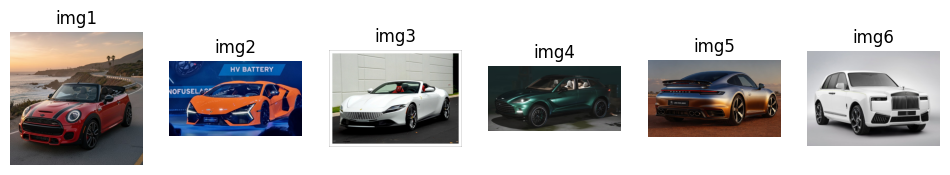

In [ ]:
import cv2
from google.colab.patches import cv2_imshow
import numpy as np
import matplotlib.pyplot as plt

img1 = cv2.imread('미니쿠퍼.jpeg')
img2 = cv2.imread('람보르기니.jpeg')
img3 = cv2.imread('페라리.jpeg')
img4 = cv2.imread('에스터마틴.jpeg')
img5 = cv2.imread('포르쉐.jpeg')
img6 = cv2.imread('롤스로이스.jpeg')

images = [img1, img2, img3, img4, img5, img6]

hists = []
for i, img in enumerate(images):
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    hist = cv2.calcHist([hsv], [0, 1], None, [180, 256], [0, 180, 0, 256])
    cv2.normalize(hist, hist, 0, 1, cv2.NORM_MINMAX)
    hists.append(hist)

query = hists[0]
methods = {
    'CORREL' : cv2.HISTCMP_CORREL,
    'CHISQR' : cv2.HISTCMP_CHISQR,
    'INTERSECT' : cv2.HISTCMP_INTERSECT,
    'BHATTACHARYYA' : cv2.HISTCMP_BHATTACHARYYA
}

for name, flag in methods.items():
    print(f"%-13s" % name, end="\t")
    for i, (hist, img) in enumerate(zip(hists, images)):
        ret = cv2.compareHist(query, hist, flag)
        if flag==cv2.HISTCMP_INTERSECT:
           ret = ret / np.sum(query)
        print(f"img{i+1}: {ret: 2f}", end="\t")
    print()

plt.figure(figsize=(12, 4))
for i, img in enumerate(images):
    plt.subplot(1, len(images), i+1)
    plt.title(f'img{i+1}')
    plt.axis('off')
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.show()

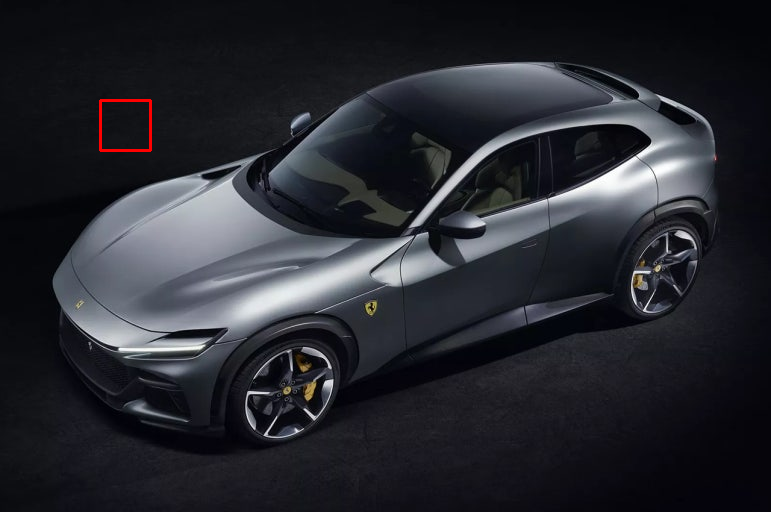

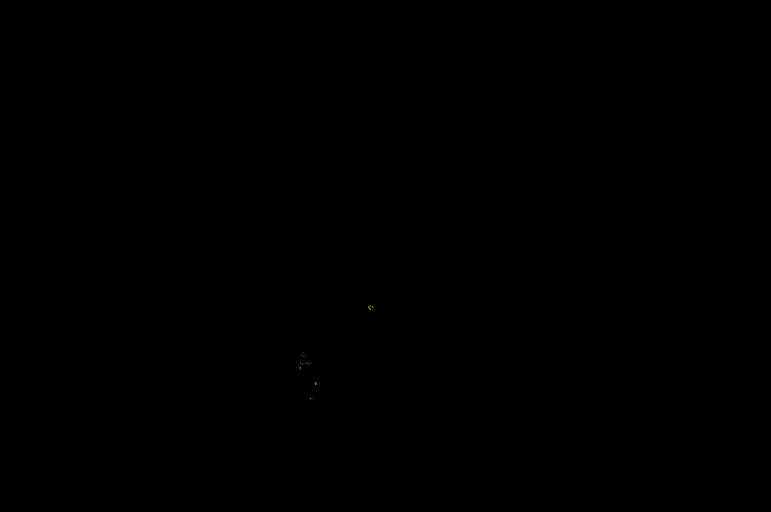

In [ ]:
import cv2
from google.colab.patches import cv2_imshow
import numpy as np
import matplotlib.pyplot as plt

image = cv2.imread('페라리suv.jpeg')
hsvImage = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
draw = image.copy()

def masking(bp):
    disc = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
    cv2.filter2D(bp, -1, disc, bp)
    _, mask = cv2.threshold(bp, 1, 255, cv2.THRESH_BINARY)
    result = cv2.bitwise_and(image, image, mask=mask)
    cv2_imshow(result)

def backproject_cv(hist_roi):
    bp = cv2.calcBackProject([hsvImage], [0, 1], hist_roi, [0, 100, 0, 256], 1)
    masking(bp)

(x, y, w, h) = (100, 100, 50, 50)

if w > 0 and h > 0:
    roi = draw[y:y+h, x:x+w]
    cv2.rectangle(draw, (x, y), (x+w, y+h), (0, 0, 255), 2)
    cv2_imshow(draw)

    hsv_roi = cv2.cvtColor(roi, cv2.COLOR_BGR2HSV)
    hist_roi = cv2.calcHist([hsv_roi], [0, 1], None, [100, 256], [0, 100, 0, 256])

    backproject_cv(hist_roi)